# TRUSTSR Lab 03.03 — Independent Failure Journal and Reconciliation

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 03 — Reliability and evidence integrity  
**Status:** Synthetic local prototype | Version 0.1.0

## Motivation
Lab 03.02 showed that a post-rollback failure record can be absent if the failure recorder itself is unavailable. This lab adds an **independent local journal** and a reconciliation step to detect missing primary audit records.

The independent journal is a second SQLite database file, separate from the primary checkpoint/audit database. This is useful for testing separation of failure domains, but it is **not** a remote service and does not guarantee survival of machine, disk, or host-wide failures.

## Tests
1. Successful checkpoint is recorded in primary audit and independent journal.
2. Injected pre-commit failure rolls back the primary transaction and is recorded in the independent journal.
3. Simulate an absent primary audit record and reconcile journal entries against primary audit transaction IDs.
4. Simulate the independent journal being unavailable; report the remaining observability gap.
5. Verify journal hash chain, restart persistence, assertions, plots, and CSV exports.

**Evidence boundary:** All scenarios are synthetic local simulations. No real crash, host outage, production deployment, or security guarantee is demonstrated.

## 1. Imports and create two separate databases

In [1]:
import os, json, sqlite3, tempfile, hashlib, uuid, sys
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic local simulation")

def temp_db(prefix):
    fd, path = tempfile.mkstemp(prefix=prefix, suffix=".sqlite")
    os.close(fd)
    return path

PRIMARY_PATH = temp_db("trustsr_primary_")
JOURNAL_PATH = temp_db("trustsr_independent_journal_")

def connect_primary():
    c = sqlite3.connect(PRIMARY_PATH, timeout=10, isolation_level=None)
    c.execute("PRAGMA journal_mode=WAL")
    c.execute("PRAGMA synchronous=FULL")
    c.execute("CREATE TABLE IF NOT EXISTS checkpoint_state (id INTEGER PRIMARY KEY CHECK(id=1), high_water_mark INTEGER NOT NULL)")
    c.execute("INSERT OR IGNORE INTO checkpoint_state VALUES (1,0)")
    c.execute("CREATE TABLE IF NOT EXISTS primary_audit (sequence INTEGER PRIMARY KEY AUTOINCREMENT, transaction_id TEXT UNIQUE NOT NULL, timestamp_utc TEXT NOT NULL, version INTEGER, outcome TEXT NOT NULL, reason TEXT NOT NULL, mark_before INTEGER NOT NULL, mark_after INTEGER NOT NULL)")
    return c

def connect_journal():
    c = sqlite3.connect(JOURNAL_PATH, timeout=10, isolation_level=None)
    c.execute("PRAGMA journal_mode=WAL")
    c.execute("PRAGMA synchronous=FULL")
    c.execute("CREATE TABLE IF NOT EXISTS journal_events (sequence INTEGER PRIMARY KEY AUTOINCREMENT, transaction_id TEXT UNIQUE NOT NULL, timestamp_utc TEXT NOT NULL, event_type TEXT NOT NULL, version INTEGER, outcome TEXT NOT NULL, reason TEXT NOT NULL, mark_before INTEGER NOT NULL, mark_after INTEGER NOT NULL, previous_hash TEXT NOT NULL, event_hash TEXT NOT NULL)")
    return c

primary = connect_primary()
journal = connect_journal()
print("Primary mark:", primary.execute("SELECT high_water_mark FROM checkpoint_state").fetchone()[0])

Python: 3.12.3
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:26:34.599433+00:00
Evidence classification: synthetic local simulation
Primary mark: 0


## 2. Hash-chain journal and primary audit helpers

In [2]:
GENESIS = "0" * 64

def canon(x):
    return json.dumps(x, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode()

def digest(x):
    return hashlib.sha256(canon(x)).hexdigest()

JOURNAL_FIELDS = ["sequence","transaction_id","timestamp_utc","event_type","version","outcome","reason","mark_before","mark_after","previous_hash"]

def append_journal(txid, event_type, version, outcome, reason, before, after, *, simulate_unavailable=False):
    if simulate_unavailable:
        return False
    previous = journal.execute("SELECT event_hash FROM journal_events ORDER BY sequence DESC LIMIT 1").fetchone()
    prev_hash = previous[0] if previous else GENESIS
    seq = int(journal.execute("SELECT COALESCE(MAX(sequence),0)+1 FROM journal_events").fetchone()[0])
    event = {"sequence":seq,"transaction_id":txid,"timestamp_utc":datetime.now(timezone.utc).isoformat(),
             "event_type":event_type,"version":version,"outcome":outcome,"reason":reason,
             "mark_before":before,"mark_after":after,"previous_hash":prev_hash}
    journal.execute("INSERT INTO journal_events (sequence,transaction_id,timestamp_utc,event_type,version,outcome,reason,mark_before,mark_after,previous_hash,event_hash) VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                    (seq,txid,event["timestamp_utc"],event_type,version,outcome,reason,before,after,prev_hash,digest(event)))
    return True

def fetch_journal():
    rows = journal.execute("SELECT sequence,transaction_id,timestamp_utc,event_type,version,outcome,reason,mark_before,mark_after,previous_hash,event_hash FROM journal_events ORDER BY sequence").fetchall()
    return [dict(zip(JOURNAL_FIELDS+["event_hash"], row)) for row in rows]

def verify_journal(events):
    issues, prev = [], GENESIS
    for expected, stored in enumerate(events, start=1):
        payload = {k:stored[k] for k in JOURNAL_FIELDS}
        if stored["sequence"] != expected: issues.append("sequence_gap")
        if stored["previous_hash"] != prev: issues.append("previous_hash_mismatch")
        if stored["event_hash"] != digest(payload): issues.append("event_hash_mismatch")
        prev = stored["event_hash"]
    return {"valid":not issues,"issues":issues,"events_checked":len(events)}

def primary_txids():
    return {r[0] for r in primary.execute("SELECT transaction_id FROM primary_audit").fetchall()}

print("Journal helpers ready.")

Journal helpers ready.


## 3. Submit checkpoint with independent journaling

In [3]:
def submit(version, *, inject_precommit_failure=False, journal_unavailable=False):
    txid = str(uuid.uuid4())
    primary.execute("BEGIN IMMEDIATE")
    before = int(primary.execute("SELECT high_water_mark FROM checkpoint_state WHERE id=1").fetchone()[0])
    valid = isinstance(version,int) and not isinstance(version,bool) and version >= 1
    accepted = valid and version > before
    if not valid:
        outcome, reason, after = "rejected", "invalid_version", before
    elif accepted:
        outcome, reason, after = "accepted", "committed", version
        primary.execute("UPDATE checkpoint_state SET high_water_mark=? WHERE id=1",(version,))
    else:
        outcome, reason, after = "rejected", "stale_or_replay", before
    try:
        if inject_precommit_failure:
            raise RuntimeError("injected_precommit_failure")
        primary.execute("INSERT INTO primary_audit (transaction_id,timestamp_utc,version,outcome,reason,mark_before,mark_after) VALUES (?,?,?,?,?,?,?)",
                        (txid,datetime.now(timezone.utc).isoformat(),version if valid else None,outcome,reason,before,after))
        primary.execute("COMMIT")
        journal_ok = append_journal(txid,"checkpoint_decision",version if valid else None,outcome,reason,before,after,simulate_unavailable=journal_unavailable)
        return {"transaction_id":txid,"accepted":bool(accepted),"reason":reason,"mark_before":before,"mark_after":after,"primary_audit_written":True,"journal_written":journal_ok}
    except Exception as exc:
        primary.execute("ROLLBACK")
        unchanged = int(primary.execute("SELECT high_water_mark FROM checkpoint_state WHERE id=1").fetchone()[0])
        journal_ok = append_journal(txid,"operational_failure",version if valid else None,"failed",str(exc),unchanged,unchanged,simulate_unavailable=journal_unavailable)
        return {"transaction_id":txid,"accepted":False,"reason":str(exc),"mark_before":before,"mark_after":unchanged,"primary_audit_written":False,"journal_written":journal_ok}

print("Submit function ready.")

Submit function ready.


## 4. Run controlled synthetic scenarios

In [4]:
scenario_rows = []

def run_case(name, version, expected_accept, expected_mark, **kwargs):
    result = submit(version, **kwargs)
    row = {"scenario":name,"version":version,"accepted":result["accepted"],"reason":result["reason"],
           "mark_before":result["mark_before"],"mark_after":result["mark_after"],
           "primary_audit_written":result["primary_audit_written"],"journal_written":result["journal_written"],
           "transaction_id":result["transaction_id"],
           "assertion_passed":result["accepted"]==expected_accept and result["mark_after"]==expected_mark}
    scenario_rows.append(row)
    assert row["assertion_passed"], row
    return result

run_case("accepted_checkpoint",2,True,2)
run_case("rejected_stale_checkpoint",1,False,2)
run_case("injected_primary_precommit_failure",4,False,2,inject_precommit_failure=True)
run_case("accepted_checkpoint_after_failure",3,True,3)
run_case("failure_with_journal_unavailable",5,False,3,inject_precommit_failure=True,journal_unavailable=True)

scenario_df = pd.DataFrame(scenario_rows)
display(scenario_df)
print("Primary audit rows:", primary.execute("SELECT COUNT(*) FROM primary_audit").fetchone()[0])
print("Independent journal rows:", journal.execute("SELECT COUNT(*) FROM journal_events").fetchone()[0])

                             scenario  version  accepted                      reason  mark_before  mark_after  primary_audit_written  journal_written                        transaction_id  \
0                 accepted_checkpoint        2      True                   committed            0           2                   True             True  9fa2e34b-7c8b-44a4-a8a6-4ce4c0996338   
1           rejected_stale_checkpoint        1     False             stale_or_replay            2           2                   True             True  2e0b6019-d675-479f-85bf-886c9a5130d8   
2  injected_primary_precommit_failure        4     False  injected_precommit_failure            2           2                  False             True  624b8993-add6-47c1-ad85-8db69f02fea5   
3   accepted_checkpoint_after_failure        3      True                   committed            2           3                   True             True  278aa35a-2a69-4931-a241-48c5eeaae235   
4    failure_with_journal_unavailable        

Primary audit rows: 3
Independent journal rows: 4


## 5. Reconcile journal against primary audit

In [5]:
def reconcile():
    primary_ids = primary_txids()
    reports = []
    for event in fetch_journal():
        present = event["transaction_id"] in primary_ids
        is_failure = event["event_type"] == "operational_failure"
        # Failure events are expected not to have a primary decision row after rollback.
        status = "expected_failure_without_primary_row" if is_failure and not present else (
            "missing_primary_audit_for_decision" if not present else "matched_primary_audit")
        reports.append({"transaction_id":event["transaction_id"],"event_type":event["event_type"],
                        "primary_audit_present":present,"reconciliation_status":status})
    # Also detect primary audit decisions that have no journal entry.
    journal_ids = {e["transaction_id"] for e in fetch_journal()}
    for txid in sorted(primary_ids - journal_ids):
        reports.append({"transaction_id":txid,"event_type":"primary_decision","primary_audit_present":True,
                        "reconciliation_status":"missing_independent_journal_entry"})
    return pd.DataFrame(reports)

reconciliation_df = reconcile()
display(reconciliation_df)
assert "expected_failure_without_primary_row" in set(reconciliation_df["reconciliation_status"])
assert "missing_independent_journal_entry" in set(reconciliation_df["reconciliation_status"]) or scenario_df.loc[scenario_df["scenario"]=="failure_with_journal_unavailable","journal_written"].iloc[0] == False
print("Reconciliation reports journal-only failures and any missing journal entries for primary decisions.")

                         transaction_id           event_type  primary_audit_present                 reconciliation_status
0  9fa2e34b-7c8b-44a4-a8a6-4ce4c0996338  checkpoint_decision                   True                 matched_primary_audit
1  2e0b6019-d675-479f-85bf-886c9a5130d8  checkpoint_decision                   True                 matched_primary_audit
2  624b8993-add6-47c1-ad85-8db69f02fea5  operational_failure                  False  expected_failure_without_primary_row
3  278aa35a-2a69-4931-a241-48c5eeaae235  checkpoint_decision                   True                 matched_primary_audit

Reconciliation reports journal-only failures and any missing journal entries for primary decisions.


## 6. Demonstrate a missing journal entry and restart persistence

In [6]:
# The last scenario simulated a failure while the independent journal was unavailable.
missing_journal_row = scenario_df.loc[scenario_df["scenario"]=="failure_with_journal_unavailable"].iloc[0]
assert not bool(missing_journal_row["journal_written"])

mark_before_restart = int(primary.execute("SELECT high_water_mark FROM checkpoint_state WHERE id=1").fetchone()[0])
primary_rows_before = int(primary.execute("SELECT COUNT(*) FROM primary_audit").fetchone()[0])
journal_rows_before = len(fetch_journal())
primary.close(); journal.close()
primary = connect_primary(); journal = connect_journal()
restart = {
    "mark_before":mark_before_restart,
    "mark_after":int(primary.execute("SELECT high_water_mark FROM checkpoint_state WHERE id=1").fetchone()[0]),
    "primary_rows_before":primary_rows_before,
    "primary_rows_after":int(primary.execute("SELECT COUNT(*) FROM primary_audit").fetchone()[0]),
    "journal_rows_before":journal_rows_before,
    "journal_rows_after":len(fetch_journal())
}
restart["state_persisted"] = restart["mark_before"] == restart["mark_after"]
restart["primary_audit_persisted"] = restart["primary_rows_before"] == restart["primary_rows_after"]
restart["journal_persisted"] = restart["journal_rows_before"] == restart["journal_rows_after"]
display(pd.DataFrame([restart]))
assert restart["state_persisted"] and restart["primary_audit_persisted"] and restart["journal_persisted"]

   mark_before  mark_after  primary_rows_before  primary_rows_after  journal_rows_before  journal_rows_after  state_persisted  primary_audit_persisted  journal_persisted
0            3           3                    3                   3                    4                   4             True                     True               True

## 7. Verify chain, export results, and plot

Independent journal chain: {'valid': True, 'issues': [], 'events_checked': 4}


                              test  passed
0              journal_chain_valid    True
1          restart_state_persisted    True
2  restart_primary_audit_persisted    True
3        restart_journal_persisted    True
4  journal_unavailable_gap_visible    True

CSV exports created: scenarios, independent_journal, reconciliation, validation, restart.


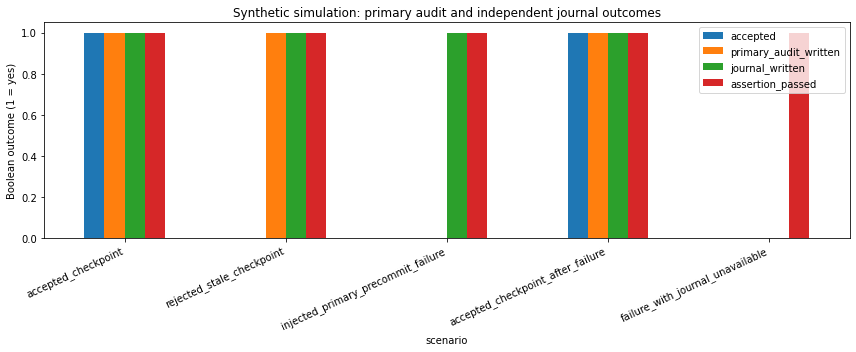

In [7]:
events = fetch_journal()
chain_check = verify_journal(events)
print("Independent journal chain:", chain_check)
assert chain_check["valid"]

validation_df = pd.DataFrame([
    {"test":"journal_chain_valid","passed":chain_check["valid"]},
    {"test":"restart_state_persisted","passed":restart["state_persisted"]},
    {"test":"restart_primary_audit_persisted","passed":restart["primary_audit_persisted"]},
    {"test":"restart_journal_persisted","passed":restart["journal_persisted"]},
    {"test":"journal_unavailable_gap_visible","passed":not bool(missing_journal_row["journal_written"])}
])
display(validation_df)
assert validation_df["passed"].all()

scenario_df.to_csv("trustsr_lab03_03_scenarios.csv",index=False)
pd.DataFrame(events).to_csv("trustsr_lab03_03_independent_journal.csv",index=False)
reconciliation_df.to_csv("trustsr_lab03_03_reconciliation.csv",index=False)
validation_df.to_csv("trustsr_lab03_03_validation.csv",index=False)
pd.DataFrame([restart]).to_csv("trustsr_lab03_03_restart.csv",index=False)

ax = scenario_df.set_index("scenario")[["accepted","primary_audit_written","journal_written","assertion_passed"]].astype(int).plot(kind="bar",figsize=(12,5))
ax.set_title("Synthetic simulation: primary audit and independent journal outcomes")
ax.set_ylabel("Boolean outcome (1 = yes)")
plt.xticks(rotation=25,ha="right")
plt.tight_layout()
plt.show()

print("CSV exports created: scenarios, independent_journal, reconciliation, validation, restart.")

## 8. Final assertions and interpretation

```text
All TRUSTSR Lab 03.03 assertions passed.
```

### Defensible synthetic finding
In these controlled scenarios, the separate journal recorded a simulated primary pre-commit failure when the journal was available. Reconciliation distinguished failure events that correctly lacked a primary decision row from primary decisions lacking a journal entry. When the independent journal was simulated as unavailable, the failure remained unrecorded there.

### Limitations
- Both databases are on the same local host and storage; this is not independent disaster recovery.
- The journal write happens after the primary transaction, so a process or host failure between them can still create a gap.
- A simulated unavailable journal is not a real service outage.
- No production crash testing, remote replication, trusted external anchor, or real agent execution is covered.
- Passing assertions establishes only these synthetic cases.

### Next engineering step
If stronger failure evidence is required, define an actual failure-domain boundary (for example, a separately operated remote logging service) and test timeout, network partition, retry, duplicate delivery, and reconciliation semantics. Do not call a second local database “tamper-proof” or “crash-proof.”